In [8]:
import scanpy as sc 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import os

In [9]:
save_dir = 'req_3_expression'
os.makedirs(save_dir, exist_ok=True)

## rna marker plot

In [10]:
scdata = sc.read_h5ad('../data/final_anno.h5ad')

eco marker
neco marker


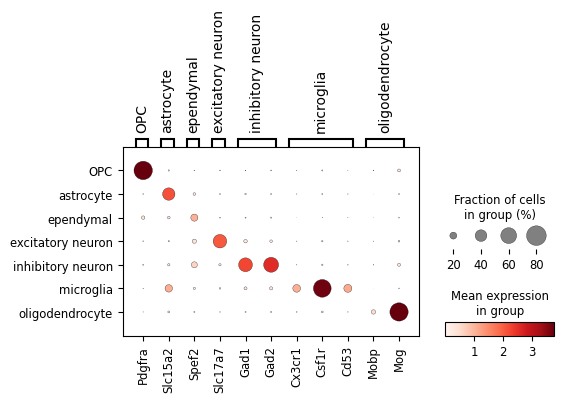

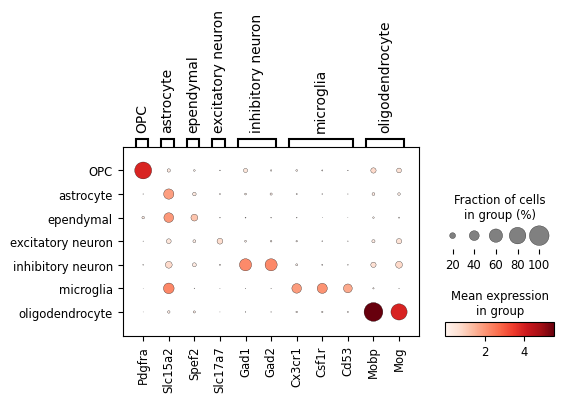

In [11]:
marker_dic = {
    'OPC': ['Pdgfra'],
    'astrocyte': ['Slc15a2'],
    'ependymal': ['Spef2'],
    'excitatory neuron': ['Slc17a7'],
    'inhibitory neuron': ['Gad1','Gad2'],
    'microglia': ['Cx3cr1','Csf1r','Cd53'],
    'oligodendrocyte': ['Mobp','Mog'],
}

idx = scdata.obs.species.isin(['CY','JT','T'])

print('eco marker')
sc.pl.dotplot(scdata[idx,:], var_names = marker_dic,groupby = 'celltype', cmap = 'Reds', show = False)
plt.savefig(os.path.join(save_dir, f'rna_marker_eco.pdf'), bbox_inches='tight', dpi = 600)
print('neco marker')
sc.pl.dotplot(scdata[~idx,:], var_names = marker_dic,groupby = 'celltype', cmap = 'Reds',show = False)
plt.savefig(os.path.join(save_dir, f'rna_marker_neco.pdf'), bbox_inches='tight', dpi = 600)


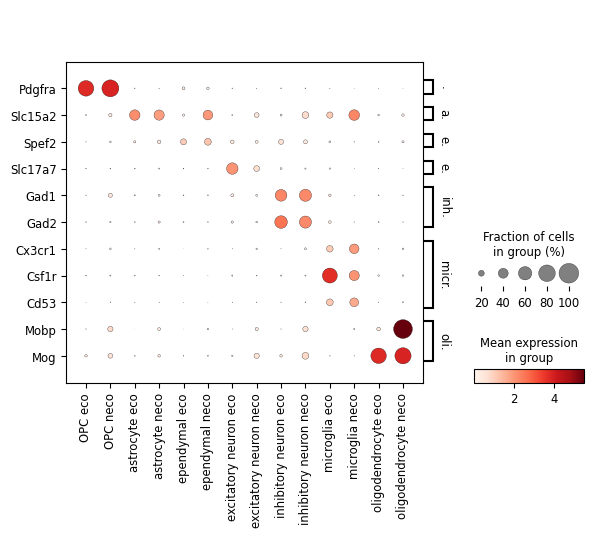

In [12]:
eco_map = {'CY': 'eco',
           'JT': 'eco',
           'T': 'eco',
           'QF': 'neco',
           'M': 'neco'}
scdata.obs.loc[:,'eco'] = scdata.obs.species.map(eco_map) 

scdata.obs.loc[:,'new_cluster'] =  scdata.obs.celltype.astype(object) + ' ' + scdata.obs.eco.astype(object)
sc.pl.dotplot(scdata, var_names = marker_dic, swap_axes= True, groupby='new_cluster',dendrogram=False, 
              show = False)
plt.savefig(os.path.join(save_dir, f'rna_marker_joint_dotplot.pdf'), bbox_inches='tight', dpi = 600)

## gadata 尝试

eco marker
neco marker


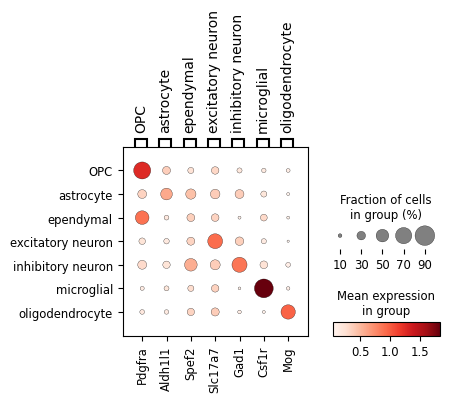

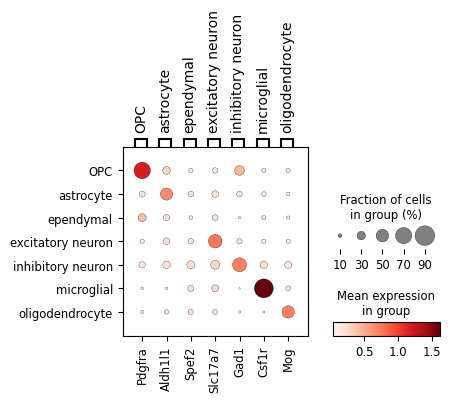

In [13]:
scdata = sc.read_h5ad('../sly_05_require/ga_plot.h5ad')
marker_dic = {'OPC': ['Pdgfra'],
              'astrocyte': ['Aldh1l1'],
              'ependymal': ['Spef2'],
              'excitatory neuron': ['Slc17a7'],
              'inhibitory neuron': ['Gad1'],
              'microglial': ['Csf1r'],   
              'oligodendrocyte': ['Mog'],}
idx = scdata.obs.species.isin(['cy','jt','t'])

print('eco marker')
sc.pl.dotplot(scdata[idx,:], var_names = marker_dic,groupby = 'fine_anno', cmap = 'Reds', show = False,)
plt.savefig(os.path.join(save_dir, f'ga_marker_eco.pdf'), bbox_inches='tight', dpi = 600)
print('neco marker')
sc.pl.dotplot(scdata[~idx,:], var_names = marker_dic,groupby = 'fine_anno', cmap = 'Reds',show = False)
plt.savefig(os.path.join(save_dir, f'ga_marker_neco.pdf'), bbox_inches='tight', dpi = 600)


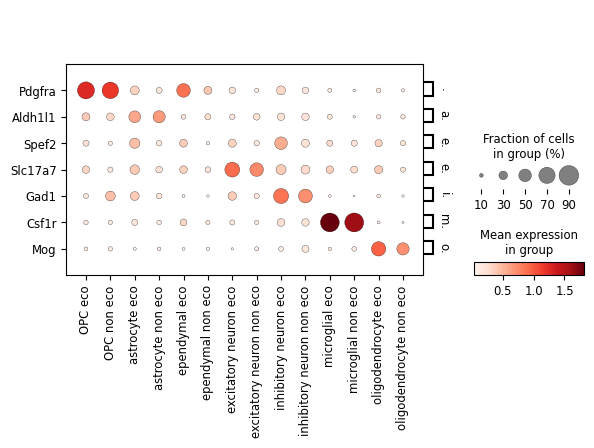

In [14]:
# eco_map = {'CY': 'eco',
#            'JT': 'eco',
#            'T': 'eco',
#            'QF': 'neco',
#            'M': 'neco'}
# scdata.obs.loc[:,'eco'] = scdata.obs.species.map(eco_map) 

scdata.obs.loc[:,'new_cluster'] =  scdata.obs.fine_anno.astype(object) + ' ' + scdata.obs.eco.astype(object)
sc.pl.dotplot(scdata, var_names = marker_dic, swap_axes= True, groupby='new_cluster',dendrogram=False,
              show = False)
plt.savefig(os.path.join(save_dir, f'ga_marker_joint_dotplot.pdf'), bbox_inches='tight', dpi = 600)